[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/hentablihamza/practical-biopython-course/blob/main/notebooks/08_blast_search_parsing.ipynb)

# 08 · BLAST: Searching for Homologues and Parsing Results

*Practical Biopython Course · Hamza Hentabli, Ph.D. · ~50 min*

BLAST finds sequences in a database that are similar to your query. In target-based drug discovery
it answers questions like *"which other proteins share this binding domain?"* (possible off-targets) or
*"which model organisms have an orthologue?"*. Our query is the **EGFR kinase domain** (UniProt P00533,
residues 712–979), searched against **Swiss-Prot** (reviewed UniProt proteins).

A remote BLAST job can wait in NCBI's queue for many minutes (sometimes far longer), so this notebook reads
a **cached XML result** by default (`data/blast_cache/`). That file was produced with the stand-alone
**BLAST+** program `blastp` against NCBI's own preformatted Swiss-Prot database; it has exactly the same
XML format as a web BLAST result (`data/provenance.json` records the versions and dates). Set
`RUN_LIVE_BLAST = True` to submit your own job to NCBI.

**Learning objectives.** By the end of this notebook you will be able to:

- submit a BLAST search to NCBI from Python with `NCBIWWW.qblast` (and know when not to)
- parse BLAST XML with `Bio.Blast.NCBIXML` into hits and HSPs
- turn hits into a table: E-value, bit score, identity, coverage, organism
- interpret BLAST statistics and filter hits sensibly

In [1]:
# Setup: installs dependencies on Google Colab and locates the course data.
# Running locally? Install requirements.txt once and this cell does nothing extra.
import os, sys, subprocess

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", 'biopython'], check=True)
    if not os.path.isdir("practical-biopython-course"):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/hentablihamza/practical-biopython-course.git"], check=True)
    DATA_DIR = "practical-biopython-course/data"
else:
    DATA_DIR = "../data" if os.path.isdir("../data") else "data"

print("Running on Colab:", IN_COLAB, "| data folder:", DATA_DIR)

Running on Colab: False | data folder: ../data


## 1. The query

In [2]:
import os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from Bio import SeqIO
from Bio.Blast import NCBIWWW, NCBIXML

CACHE = f"{DATA_DIR}/blast_cache"
query = SeqIO.read(f"{CACHE}/EGFR_kinase_domain_query.fasta", "fasta")
print(query.id, len(query), "aa")
print(query.seq)

EGFR_HUMAN_kinase_712-979 268 aa
FKKIKVLGSGAFGTVYKGLWIPEGEKVKIPVAIKELREATSPKANKEILDEAYVMASVDNPHVCRLLGICLTSTVQLITQLMPFGCLLDYVREHKDNIGSQYLLNWCVQIAKGMNYLEDRRLVHRDLAARNVLVKTPQHVKITDFGLAKLLGAEEKEYHAEGGKVPIKWMALESILHRIYTHQSDVWSYGVTVWELMTFGSKPYDGIPASEISSILEKGERLPQPPICTIDVYMIMVKCWMIDADSRPKFRELIIEFSKMARDPQRYL


## 2. Running BLAST at NCBI (optional)

`NCBIWWW.qblast(program, database, sequence)` submits the job, polls until it finishes, and returns
a handle to the XML result. Be considerate: NCBI asks for no more than one request every 10 seconds,
and you should save the result rather than re-running the same search.

In [3]:
RUN_LIVE_BLAST = False                 # set to True to run your own search (takes minutes)
OFFLINE = os.environ.get("COURSE_OFFLINE") == "1"
xml_path = f"{CACHE}/EGFR_kinase_blastp_swissprot.xml"

if RUN_LIVE_BLAST and not OFFLINE:
    os.makedirs("output", exist_ok=True)
    try:
        handle = NCBIWWW.qblast("blastp", "swissprot", str(query.seq), hitlist_size=50, expect=1e-10)
        xml_path = "output/my_blast.xml"
        with open(xml_path, "w") as out:
            out.write(handle.read())
        print("live BLAST finished ->", xml_path)
    except Exception as err:
        print("BLAST failed, using the cached result:", err)
print("reading", xml_path)
with open(f"{DATA_DIR}/provenance.json") as fh:
    print(json.dumps(json.load(fh)["blast"], indent=2))

reading ../data/blast_cache/EGFR_kinase_blastp_swissprot.xml
{
  "retrieved": "2026-11-24",
  "how": "local blastp: 2.17.0+ against NCBI's preformatted swissprot database",
  "database": "swissprot (https://ftp.ncbi.nlm.nih.gov/blast/db/swissprot.tar.gz)",
  "database_date": "Nov 15, 2026  5:53 AM",
  "program": "blastp",
  "query": "P00533 residues 712-979",
  "max_target_seqs": 50,
  "expect": 1e-10,
  "matrix": "BLOSUM62"
}


## 3. Parsing the XML

In [4]:
with open(xml_path) as fh:
    blast_record = NCBIXML.read(fh)          # one query -> one record (use NCBIXML.parse for many)

print("program:", blast_record.application, blast_record.version)
print("database:", blast_record.database, "|", blast_record.database_sequences, "sequences")
print("query length:", blast_record.query_letters)
print("hits returned:", len(blast_record.alignments))

program: BLASTP 2.17.0+
database: swissprot | 488044 sequences
query length: 268
hits returned: 50


The structure is **record → alignments (one per database hit) → HSPs** (high-scoring segment pairs,
the locally aligned regions). Most hits have one HSP; multi-domain proteins can have several.

In [5]:
top = blast_record.alignments[0]
hsp = top.hsps[0]
print(top.hit_def[:100])
print("accession:", top.accession, "| length:", top.length)
print(f"bit score {hsp.bits:.1f} | E-value {hsp.expect:.2e} | identities {hsp.identities}/{hsp.align_length}")
print(hsp.query[:60]); print(hsp.match[:60]); print(hsp.sbjct[:60])

RecName: Full=Epidermal growth factor receptor; Flags: Precursor [Macaca mulatta]
accession: P55245 | length: 1210
bit score 561.2 | E-value 0.00e+00 | identities 268/268
FKKIKVLGSGAFGTVYKGLWIPEGEKVKIPVAIKELREATSPKANKEILDEAYVMASVDN
FKKIKVLGSGAFGTVYKGLWIPEGEKVKIPVAIKELREATSPKANKEILDEAYVMASVDN
FKKIKVLGSGAFGTVYKGLWIPEGEKVKIPVAIKELREATSPKANKEILDEAYVMASVDN


## 4. A hit table

In [6]:
import re

def parse_hit_def(hit_def):
    """Swiss-Prot titles look like 'RecName: Full=Protein name; AltName: ...; Flags: ... [Organism]'."""
    organisms = re.findall(r"\[([^\[\]]+)\]", hit_def)
    name = hit_def.split(";")[0].replace("RecName: Full=", "").split(" [")[0]
    return name, (organisms[-1] if organisms else "")

rows = []
for aln in blast_record.alignments:
    h = aln.hsps[0]                                     # best HSP per hit
    protein, organism = parse_hit_def(aln.hit_def)
    rows.append({
        "accession": aln.accession,
        "protein": protein[:45],
        "organism": organism,
        "evalue": h.expect, "bits": round(h.bits, 1),
        "identity_%": round(100 * h.identities / h.align_length, 1),
        "query_cov_%": round(100 * (h.query_end - h.query_start + 1) / blast_record.query_letters, 1),
        "sbjct_range": f"{h.sbjct_start}-{h.sbjct_end}",
    })
hits = pd.DataFrame(rows)
print(len(hits), "hits")
hits.head(15)

50 hits


,accession,protein,organism,evalue,bits,identity_%,query_cov_%,sbjct_range
0,P55245,Epidermal growth factor receptor,Macaca mulatta,0.000000e+00,561.2,100.0,100.0,712-979
1,P00533,Epidermal growth factor receptor,Homo sapiens,0.000000e+00,560.8,100.0,100.0,712-979
2,Q01279,Epidermal growth factor receptor,Mus musculus,0.000000e+00,555.4,98.9,100.0,714-981
3,P00534,Tyrosine-protein kinase transforming protein,Avian leukosis virus,0.000000e+00,549.7,97.0,100.0,132-399
4,P00535,Tyrosine-protein kinase transforming protein,Avian erythroblastosis virus (strain ES4),0.000000e+00,549.3,96.6,100.0,132-399
5,P11273,Tyrosine-protein kinase transforming protein,Avian erythroblastosis virus (strain ts167),0.000000e+00,535.4,94.8,100.0,132-399
6,P13388,Melanoma receptor tyrosine-protein kinase,Xiphophorus maculatus,1.200810e-158,473.8,81.7,100.0,710-977
7,P06494,Receptor tyrosine-protein kinase erbB-2,Rattus norvegicus,5.737630e-157,471.9,82.1,100.0,722-989
8,P70424,Receptor tyrosine-protein kinase erbB-2,Mus musculus,4.218640e-156,469.5,81.7,100.0,721-988
9,O18735,Receptor tyrosine-protein kinase erbB-2,Canis lupus familiaris,4.675010e-156,469.2,81.7,100.0,719-986


## 5. Reading the statistics

- **E-value**: the number of hits this good expected by chance in a database this size. Lower is better;
  1e-10 is already very significant.
- **Bit score**: a normalized score independent of database size; use it to rank hits.
- **Identity** and **coverage** together: a 90% identity over 20 residues is weaker evidence than 50%
  over the whole domain.

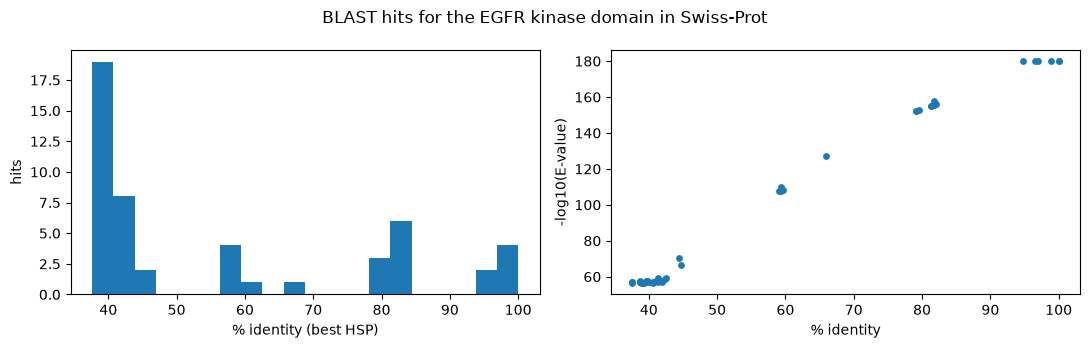

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].hist(hits["identity_%"], bins=20, color="tab:blue")
axes[0].set_xlabel("% identity (best HSP)"); axes[0].set_ylabel("hits")
axes[1].scatter(hits["identity_%"], -np.log10(hits["evalue"].clip(lower=1e-180)), s=15)
axes[1].set_xlabel("% identity"); axes[1].set_ylabel("-log10(E-value)")
plt.suptitle("BLAST hits for the EGFR kinase domain in Swiss-Prot"); plt.tight_layout(); plt.show()

## 6. Filtering: human proteins and orthologues

In [8]:
human = hits[hits["organism"] == "Homo sapiens"]
print(len(human), "human hits:")
human[["accession", "protein", "identity_%", "bits", "evalue"]]

11 human hits:


,accession,protein,identity_%,bits,evalue
1,P00533,Epidermal growth factor receptor,100.0,560.8,0.000000e+00
11,P04626,Receptor tyrosine-protein kinase erbB-2,81.3,468.0,1.181320e-155
13,Q15303,Receptor tyrosine-protein kinase erbB-4,79.1,461.8,8.835890e-153
20,P21860,Receptor tyrosine-protein kinase erbB-3,59.3,344.4,1.601830e-108
26,Q07912,Activated CDC42 kinase 1,39.7,203.8,1.606170e-58
27,P43405,Tyrosine-protein kinase SYK,41.7,199.5,1.607420e-58
29,P42684,Tyrosine-protein kinase ABL2,41.7,203.8,2.461180e-58
31,P43403,Tyrosine-protein kinase ZAP-70,39.6,198.4,4.134350e-58
37,Q05397,Focal adhesion kinase 1,38.7,201.8,7.827450e-58
47,Q14289,Protein-tyrosine kinase 2-beta,37.6,200.3,2.411780e-57


In [9]:
print("organisms among the hits:")
hits["organism"].value_counts().head(10)

organisms among the hits:


organism
Homo sapiens                                   11
Mus musculus                                   11
Rattus norvegicus                               8
Gallus gallus                                   2
Xenopus laevis                                  2
Macaca mulatta                                  1
Avian leukosis virus                            1
Avian erythroblastosis virus (strain ES4)       1
Avian erythroblastosis virus (strain ts167)     1
Xiphophorus maculatus                           1
Name: count, dtype: int64

Every protein kinase has a kinase domain, so the hit list is limited by `hitlist_size=50`, not by
significance: thousands of kinases would pass E < 1e-10. The top hits are EGFR orthologues, viral *erbB*
oncogenes (retroviruses that captured a copy of the EGFR gene), and the other ErbB receptors. Among human
proteins, ERBB2 and ERBB4 are the closest: the kinases an EGFR inhibitor is most likely to cross-react with.

## 7. Saving hit sequences

In [10]:
from Bio.Seq import Seq
from Bio.SeqRecord import SeqRecord

os.makedirs("output", exist_ok=True)
records = [SeqRecord(Seq(aln.hsps[0].sbjct.replace("-", "")), id=aln.accession,
                     description=parse_hit_def(aln.hit_def)[0]) for aln in blast_record.alignments[:10]]
SeqIO.write(records, "output/top10_hsp_sequences.fasta", "fasta")
print(open("output/top10_hsp_sequences.fasta").read()[:300])

>P55245 Epidermal growth factor receptor
FKKIKVLGSGAFGTVYKGLWIPEGEKVKIPVAIKELREATSPKANKEILDEAYVMASVDN
PHVCRLLGICLTSTVQLITQLMPFGCLLDYVREHKDNIGSQYLLNWCVQIAKGMNYLEDR
RLVHRDLAARNVLVKTPQHVKITDFGLAKLLGAEEKEYHAEGGKVPIKWMALESILHRIY
THQSDVWSYGVTVWELMTFGSKPYDGIPASEISSILEKGERLPQPPICTIDVYMIMVKCW
MIDADSRPKFRELII


These are the **aligned regions** only. To get full-length sequences, pass the accessions to
`Entrez.efetch(db="protein", ...)` (Notebook 05).

> **Newer API.** Biopython 1.84+ also offers `Bio.Blast.parse` / `Bio.Blast.read`, which return records
> whose hits are `Bio.Align.Alignment` objects. `NCBIXML` remains widely used in existing code, which is why
> it is taught here.

### ✏️ Exercise 1

How many hits have **at least 50% identity** and **at least 90% query coverage**? List their proteins and organisms.

In [11]:
# Your code here

<details>
<summary><b>Show solution</b></summary>

```python
good = hits[(hits["identity_%"] >= 50) & (hits["query_cov_%"] >= 90)]
print(len(good), "hits")
good[["protein", "organism", "identity_%"]]
```

</details>

### ✏️ Exercise 2

Which hit has the lowest identity, and what is its E-value? Is it still a convincing homologue?

In [12]:
# Your code here

<details>
<summary><b>Show solution</b></summary>

```python
worst = hits.sort_values("identity_%").iloc[0]
print(worst["protein"], "|", worst["organism"], "|", worst["identity_%"], "% | E =", worst["evalue"])
```

</details>

### ✏️ Exercise 3

Count how many hits have **more than one HSP**, and print the HSP ranges for the first such hit.

In [13]:
# Your code here

<details>
<summary><b>Show solution</b></summary>

```python
multi = [a for a in blast_record.alignments if len(a.hsps) > 1]
print(len(multi), "hits with >1 HSP")
if multi:
    for h in multi[0].hsps:
        print(multi[0].accession, h.sbjct_start, h.sbjct_end, h.expect)
```

</details>

## Key takeaways

- `NCBIWWW.qblast` runs remote BLAST; cache results and do not resubmit identical jobs.
- `NCBIXML.read/parse` → `alignments` → `hsps`; collect what you need into a pandas table.
- Rank by bit score, judge with E-value, identity *and* coverage.

**Next:** [09 · Protein analysis](09_protein_analysis.ipynb).